# 13.1 Workbook: wnioskowanie statystyczne — blok 2
**180 minut | poziom podstawowy | Python/Jupyter | praca w parach**

Główny case study to ankieta 362 studentów z pakietu Lock5Data, a drugi case study to sparowane dane o śnie i lekach dla 10 osób. Pliki znajdują się w repozytorium, w katalogu `data/`. Jeśli notebook zostanie pobrany osobno, pierwsza komórka kodu odczyta je z repozytorium online: [student_survey_lock5.csv](https://raw.githubusercontent.com/kflisikowsky/sad/main/data/student_survey_lock5.csv) oraz [sleep_paired.csv](https://raw.githubusercontent.com/kflisikowsky/sad/main/data/sleep_paired.csv).

A = osoba pisząca kod, B = osoba sprawdzająca hipotezy i założenia. Zamiana ról co zadanie. Komórki z None uzupełnij samodzielnie; podpowiedzi rozwijają się po kliknięciu.

Pakiety: numpy, pandas, matplotlib, scipy i statsmodels. W razie potrzeby uruchom w Jupyter: %pip install statsmodels.

**Rozkład czasu:** 0–45 jedna średnia i kierunek H₁; 45–60 proporcja; 60–70 przerwa; 70–105 niezależne grupy; 105–135 pary; 135–155 kategorie; 155–170 KDE; 170–180 podsumowanie.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
from pathlib import Path

plt.style.use('seaborn-v0_8-whitegrid')
DATA=Path('data')
DATA_URL='https://raw.githubusercontent.com/kflisikowsky/sad/main/data'
def read_dataset(filename):
    local_path=DATA/filename
    if local_path.exists():
        return pd.read_csv(local_path)
    return pd.read_csv(f'{DATA_URL}/{filename}')
survey=read_dataset('student_survey_lock5.csv')
sleep=read_dataset('sleep_paired.csv')

exercise=survey.Exercise.dropna().to_numpy()
tv_f=survey.loc[survey.Sex=='F','TV'].dropna().to_numpy()
tv_m=survey.loc[survey.Sex=='M','TV'].dropna().to_numpy()
drug1=sleep.drug1.to_numpy()
drug2=sleep.drug2.to_numpy()
diff=drug2-drug1
print('Ankieta:',len(survey),'odpowiedzi; sleep:',len(sleep),'par')


Ankieta: 362 odpowiedzi; sleep: 10 par


## 0–45 min. Case study A: jedna średnia
W ankiecie Exercise oznacza deklarowaną liczbę godzin aktywności fizycznej na tydzień.

**Pytanie:** czy przeciętnie jest to 8,5 godziny tygodniowo? Próg 8,5 godziny to wartość dydaktyczna, nie oficjalna rekomendacja.

H₀: μ = 8,5. Najpierw zapisz H₁, dopiero potem patrz na wyniki.


n = 361 średnia = 9.05 odchylenie = 5.74


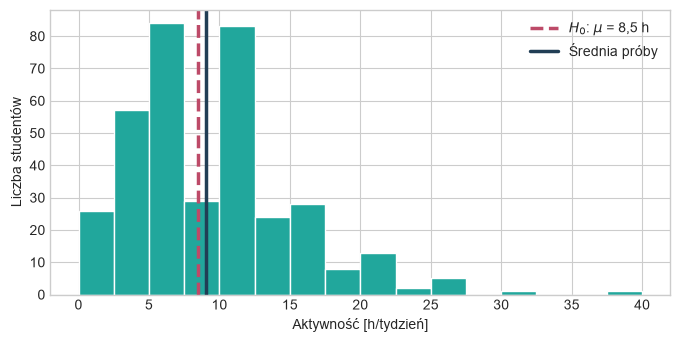

In [2]:
print('n =',len(exercise),'średnia =',exercise.mean().round(2),'odchylenie =',exercise.std(ddof=1).round(2))
fig,ax=plt.subplots(figsize=(8,3.7))
ax.hist(exercise,bins=16,color='#21a79c',edgecolor='white')
ax.axvline(8.5,color='#bd4a68',lw=2.5,ls='--',label=r'$H_0$: $\mu$ = 8,5 h')
ax.axvline(exercise.mean(),color='#213e55',lw=2.5,label='Średnia próby')
ax.set(xlabel='Aktywność [h/tydzień]',ylabel='Liczba studentów')
ax.legend();plt.show()


### Zadanie 1. Test t dla jednej średniej — DWUSTRONNY
H₁: μ ≠ 8,5. Zastosuj funkcję dla jednej próby.

**Założenia:** niezależni respondenci; pomiar ilościowy; przy mniejszej próbie w przybliżeniu normalny rozkład i brak bardzo silnych odstających. Przy n≈361 test t bywa odporny na umiarkowaną nienormalność, ale warto ocenić obserwacje odstające.


In [3]:
test_two=None  # TODO: wywołanie SciPy
if test_two is None: print('Uzupełnij test_two')
else: print('t =',round(test_two.statistic,3),'p dwustronne =',round(test_two.pvalue,5))


Uzupełnij test_two


<details style="background:#eaf7f4;padding:10px;border-radius:7px"><summary>💡 Podpowiedź 1: funkcja</summary>

stats.ttest_1samp()
</details>

<details style="background:#fff8e9;padding:10px;border-radius:7px"><summary>🔎 Podpowiedź 2: argumenty</summary>

stats.ttest_1samp(exercise, popmean=8.5, alternative="two-sided")
</details>

### Zadanie 2. Test JEDNOSTRONNY — prawostronny
Gdy **przed obejrzeniem danych** zakładamy kierunek dodatni, H₁: μ > 8,5. Przy H₁: μ < 8,5 otrzymalibyśmy test lewostronny.

W testach jednostronnych nie dzielimy mechanicznie każdego p przez dwa. Kierunek statystyki musi być zgodny z H₁.


In [4]:
test_right=None  # TODO: ta sama funkcja, inny parametr
if test_right is None: print('Uzupełnij test_right')
else: print('t =',round(test_right.statistic,3),'p prawostronne =',round(test_right.pvalue,5))


Uzupełnij test_right


<details style="background:#eaf7f4;padding:10px;border-radius:7px"><summary>💡 Podpowiedź 1: funkcja</summary>

stats.ttest_1samp()
</details>

<details style="background:#fff8e9;padding:10px;border-radius:7px"><summary>🔎 Podpowiedź 2: argumenty</summary>

Podaj alternative="greater". Dla H₁: μ < 8,5 użyłbyś alternative="less".
</details>

### Interaktywny eksperyment: jeden ogon czy dwa?
Poniższy kod rysuje dokładnie te same dane i tę samą statystykę t, ale inaczej definiuje obszar p-value. Przed uruchomieniem przewidź, czy wnioski przy α = 0,05 będą identyczne.


In [5]:
from ipywidgets import interact, Dropdown
def draw_tails(direction='two-sided'):
    t_obs=(exercise.mean()-8.5)/(exercise.std(ddof=1)/np.sqrt(len(exercise)))
    x=np.linspace(-4,4,800); y=stats.t.pdf(x,df=len(exercise)-1)
    fig,ax=plt.subplots(figsize=(8,3.7))
    ax.plot(x,y,color='#215d66',lw=2.7)
    if direction=='two-sided':
        ax.fill_between(x,0,y,where=(np.abs(x)>=abs(t_obs)),color='#ce506e',alpha=.9)
    elif direction=='greater':
        ax.fill_between(x,0,y,where=(x>=t_obs),color='#ce506e',alpha=.9)
    else:
        ax.fill_between(x,0,y,where=(x<=t_obs),color='#ce506e',alpha=.9)
    res=stats.ttest_1samp(exercise,8.5,alternative=direction)
    ax.axvline(t_obs,color='#ce506e',ls='--')
    ax.set(yticks=[],xlabel=r'Statystyka t przy $H_0$',
           title=f'$H_1$: {direction};  t={res.statistic:.3f},  p={res.pvalue:.4f}')
    plt.show()
interact(draw_tails,direction=Dropdown(options=[('dwie strony','two-sided'),('prawa','greater'),('lewa','less')],description='H₁:'));


interactive(children=(Dropdown(description='H₁:', options=(('dwie strony', 'two-sided'), ('prawa', 'greater'),…

**W parach:** zapisz obie hipotezy H₁ i obydwa p-value. Czy wolno wybrać test prawostronny dopiero po tym, jak test dwustronny okazał się nieistotny? Dlaczego nie?


## 45–60 min. Case study B: jedna proporcja
W tej samej ankiecie zmienna Smoke jest odpowiedzią Yes/No. Sprawdź, czy proporcja deklarujących palenie różni się od dydaktycznego p₀ = 20%.

**H₀: p = 0,20; H₁: p ≠ 0,20.** Wykorzystaj klasyczny test Z dla jednej proporcji.


In [6]:
k_smoke=int(survey.Smoke.eq('Yes').sum())
n_smoke=survey.Smoke.notna().sum()
print('n, Yes, udział:',n_smoke,k_smoke,round(k_smoke/n_smoke,4))
result_z=None  # TODO: gotowa funkcja z statsmodels
if result_z is None: print('Uzupełnij result_z')
else: print('z =',round(result_z[0],3),'p =',round(result_z[1],5))


n, Yes, udział: 362 43 0.1188
Uzupełnij result_z


<details style="background:#eaf7f4;padding:10px;border-radius:7px"><summary>💡 Podpowiedź 1: funkcja</summary>

statsmodels.stats.proportion.proportions_ztest()
</details>

<details style="background:#fff8e9;padding:10px;border-radius:7px"><summary>🔎 Podpowiedź 2: argumenty</summary>

proportions_ztest(count=k_smoke, nobs=n_smoke, value=.20). Funkcja zwraca parę (z, p).
</details>

Warunki: niezależni ankietowani, jednoznaczne kategorie, n·p₀≥10 i n·(1−p₀)≥10. StudentSurvey to próba wygodna — brak podstaw do wnioskowania o całej populacji studentów.

**W parach:** czym różni się jednostronny test proporcji od dwustronnego? Jak dopisać argument alternative="larger" lub "smaller" do funkcji statsmodels?


## 60–70 min. Przerwa

## 70–105 min. Case study C: dwie niezależne średnie
Porównamy tygodniowy czas oglądania TV przez kobiety (F) i mężczyzn (M). Są to dwa rozłączne zbiory respondentów.


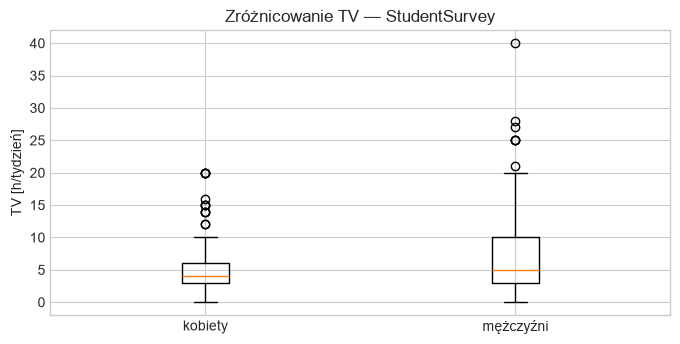

n: 169 192 średnie: 5.236686390532545 7.619791666666667


In [7]:
fig,ax=plt.subplots(figsize=(8,3.7))
ax.boxplot([tv_f,tv_m],tick_labels=['kobiety','mężczyźni'])
ax.set(ylabel='TV [h/tydzień]',title='Zróżnicowanie TV — StudentSurvey')
plt.show()
print('n:',len(tv_f),len(tv_m),'średnie:',tv_f.mean(),tv_m.mean())


### Zadanie 3. Welch
H₀: μF = μM; H₁: μF ≠ μM. Test Welcha nie wymaga równości wariancji.

Założenia: niezależność osób, dane ilościowe, brak silnych obserwacji wpływowych; w małych próbach także przybliżona normalność. Czy dane TV są prawoskośne?


In [8]:
result_welch=None  # TODO: użyj gotowej funkcji
if result_welch is None: print('Uzupełnij result_welch')
else:
    print('t =',result_welch.statistic,'p =',result_welch.pvalue)
    print('95% CI różnicy F-M:',result_welch.confidence_interval())


Uzupełnij result_welch


<details style="background:#eaf7f4;padding:10px;border-radius:7px"><summary>💡 Podpowiedź 1: funkcja</summary>

stats.ttest_ind()
</details>

<details style="background:#fff8e9;padding:10px;border-radius:7px"><summary>🔎 Podpowiedź 2: argumenty</summary>

stats.ttest_ind(tv_f, tv_m, equal_var=False) — Welch.
</details>

### Diagnostyka i alternatywa
Nie traktuj Shapiro jako automatycznej bramki. Niezależność pochodzi z projektu badania. Mann–Whitney jest zamiennikiem badającym inne aspekty rozkładów, nie zawsze same mediany.


Shapiro F: ShapiroResult(statistic=np.float64(0.8316548109545009), pvalue=np.float64(1.1080814246073763e-12))
Shapiro M: ShapiroResult(statistic=np.float64(0.8427904665842125), pvalue=np.float64(3.95506403534183e-13))
Levene: LeveneResult(statistic=np.float64(12.681801445178488), pvalue=np.float64(0.000418966330848194))


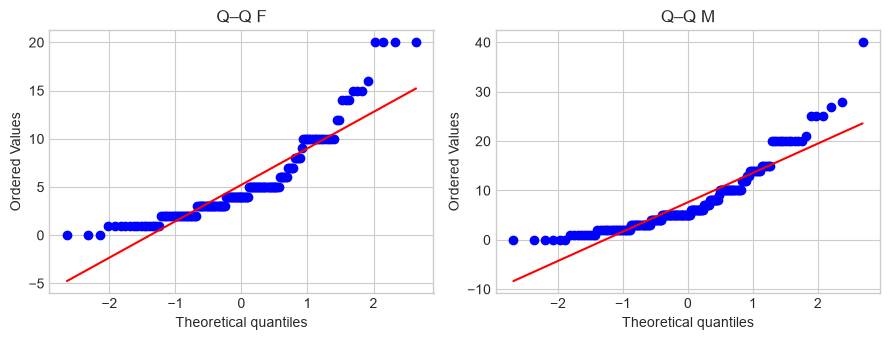

In [9]:
print('Shapiro F:',stats.shapiro(tv_f))
print('Shapiro M:',stats.shapiro(tv_m))
print('Levene:',stats.levene(tv_f,tv_m))
fig,axs=plt.subplots(1,2,figsize=(9,3.5))
stats.probplot(tv_f,dist='norm',plot=axs[0]);axs[0].set_title('Q–Q F')
stats.probplot(tv_m,dist='norm',plot=axs[1]);axs[1].set_title('Q–Q M')
plt.tight_layout();plt.show()


### Zadanie 4. Mann–Whitney: porównanie rozkładów

In [10]:
result_mw=None  # TODO
if result_mw is None: print('Uzupełnij result_mw')
else: print('U =',result_mw.statistic,'p =',result_mw.pvalue)


Uzupełnij result_mw


<details style="background:#eaf7f4;padding:10px;border-radius:7px"><summary>💡 Podpowiedź 1: funkcja</summary>

stats.mannwhitneyu()
</details>

<details style="background:#fff8e9;padding:10px;border-radius:7px"><summary>🔎 Podpowiedź 2: argumenty</summary>

stats.mannwhitneyu(tv_f, tv_m, alternative="two-sided")
</details>

## 105–135 min. Case study D: dwie obserwacje tej samej osoby
Historyczny Student’s Sleep: dodatkowe godziny snu pod wpływem leku 1 i leku 2. Jedna linia na wykresie to ta sama osoba — dane sparowane.


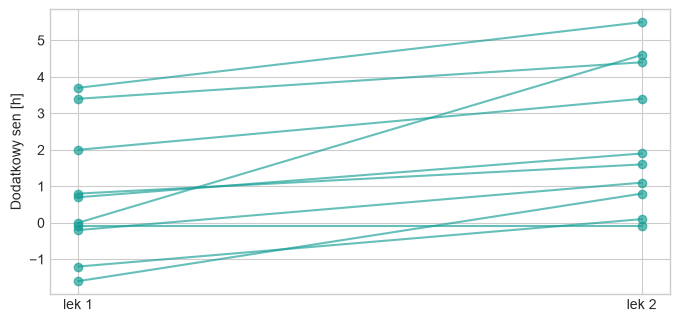

Średnia różnica lek 2 - lek 1: 1.58
Shapiro różnic: ShapiroResult(statistic=np.float64(0.8298713319287947), pvalue=np.float64(0.0333416086303077))


In [11]:
fig,ax=plt.subplots(figsize=(8,3.7))
for a,b in zip(drug1,drug2):ax.plot([1,2],[a,b],'-o',alpha=.65,color='#159d95')
ax.set(xticks=[1,2],xticklabels=['lek 1','lek 2'],ylabel='Dodatkowy sen [h]')
plt.show()
print('Średnia różnica lek 2 - lek 1:',diff.mean())
print('Shapiro różnic:',stats.shapiro(diff))


### Zadanie 5. Test t dla par
H₀: średnia różnica D=drug2−drug1 wynosi 0.

Założenia: poprawne parowanie, niezależność par, przy małym n w przybliżeniu normalny rozkład RÓŻNIC. Nie wymagamy normalności obu kolumn osobno.


In [12]:
result_paired=None  # TODO
if result_paired is None: print('Uzupełnij result_paired')
else: print(result_paired,'CI:',result_paired.confidence_interval())


Uzupełnij result_paired


<details style="background:#eaf7f4;padding:10px;border-radius:7px"><summary>💡 Podpowiedź 1: funkcja</summary>

stats.ttest_rel()
</details>

<details style="background:#fff8e9;padding:10px;border-radius:7px"><summary>🔎 Podpowiedź 2: argumenty</summary>

stats.ttest_rel(drug2, drug1)
</details>

### Zadanie 6. Wilcoxon
Alternatywa oparta na rangach |D| i ich znakach. Typowa interpretacja centrum różnic wymaga ich symetrii; uwaga na zera i remisy.


In [14]:
result_wilcoxon=None  # TODO
if result_wilcoxon is None: print('Uzupełnij result_wilcoxon')
else: print(result_wilcoxon)


Uzupełnij result_wilcoxon


<details style="background:#eaf7f4;padding:10px;border-radius:7px"><summary>💡 Podpowiedź 1: funkcja</summary>

stats.wilcoxon()
</details>

<details style="background:#fff8e9;padding:10px;border-radius:7px"><summary>🔎 Podpowiedź 2: argumenty</summary>

stats.wilcoxon(diff)
</details>

## 135–155 min. Case study E: dwie cechy kategoryczne
Czy deklaracja palenia (Smoke) zależy od płci (Sex)? Liczności z tabeli kontyngencji pozwalają przeprowadzić test niezależności χ².


Smoke   No  Yes
Sex            
F      153   16
M      166   27


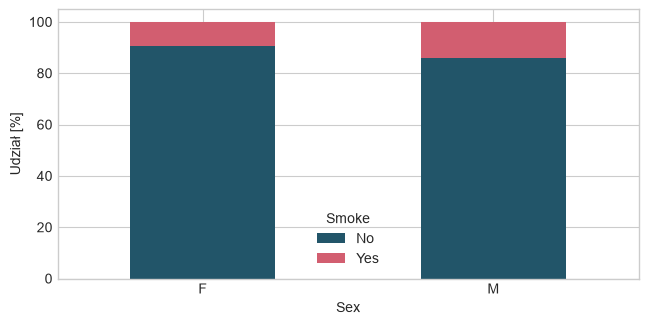

In [13]:
tab=pd.crosstab(survey.Sex,survey.Smoke)
print(tab)
(tab.div(tab.sum(axis=1),axis=0)*100).plot(kind='bar',stacked=True,figsize=(7.5,3.5),color=['#225569','#D25E70'])
plt.ylabel('Udział [%]');plt.xticks(rotation=0);plt.show()


### Zadanie 7. Test niezależności chi-kwadrat
H₀: Sex i Smoke są niezależne. Sprawdź oczekiwane liczności. Dla małych tablic 2×2 rozważ dokładny test Fishera.


In [16]:
result_chi=None  # TODO
if result_chi is None: print('Uzupełnij result_chi')
else:
    print('chi2:',result_chi.statistic,'p:',result_chi.pvalue)
    print('Min expected:',result_chi.expected_freq.min())


Uzupełnij result_chi


<details style="background:#eaf7f4;padding:10px;border-radius:7px"><summary>💡 Podpowiedź 1: funkcja</summary>

stats.chi2_contingency()
</details>

<details style="background:#fff8e9;padding:10px;border-radius:7px"><summary>🔎 Podpowiedź 2: argumenty</summary>

stats.chi2_contingency(tab), odczytaj .expected_freq
</details>

## 155–170 min. Case study F: KDE
Jądrowa estymacja gęstości opisuje kształt rozkładu godzin TV. Nie jest testem hipotez. Bandwidth decyduje o poziomie wygładzania.


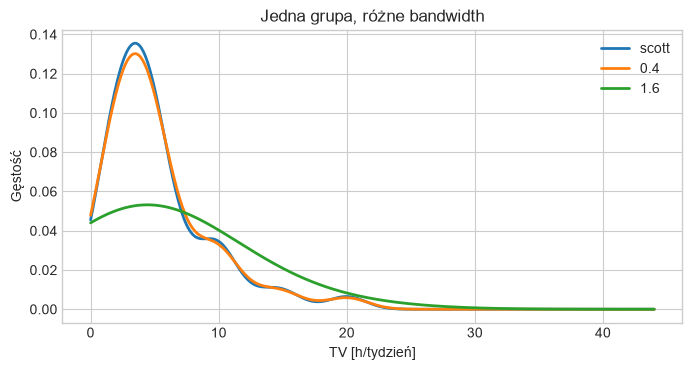

In [17]:
grid=np.linspace(0,max(tv_f.max(),tv_m.max())+4,400)
fig,ax=plt.subplots(figsize=(8,3.8))
for bw in ['scott',.4,1.6]:
    kde=stats.gaussian_kde(tv_f,bw_method=bw)
    ax.plot(grid,kde(grid),label=str(bw),lw=2)
ax.set(xlabel='TV [h/tydzień]',ylabel='Gęstość',title='Jedna grupa, różne bandwidth')
ax.legend();plt.show()


### Zadanie 8. Narysuj na jednej osi dwa KDE dla F i M. Zastosuj identyczną regułę wyboru pasma.

In [18]:
kde_f=None  # TODO
kde_m=None  # TODO
if kde_f is None or kde_m is None: print('Uzupełnij obie funkcje')
else:
    fig,ax=plt.subplots(figsize=(8,3.8))
    ax.plot(grid,kde_f(grid),label='F')
    ax.plot(grid,kde_m(grid),label='M')
    ax.legend();ax.set(xlabel='TV [h/tydzień]',ylabel='Gęstość');plt.show()


Uzupełnij obie funkcje


<details style="background:#eaf7f4;padding:10px;border-radius:7px"><summary>💡 Podpowiedź 1: funkcja</summary>

stats.gaussian_kde()
</details>

<details style="background:#fff8e9;padding:10px;border-radius:7px"><summary>🔎 Podpowiedź 2: argumenty</summary>

stats.gaussian_kde(tv_f, bw_method="scott") i osobno dla tv_m.
</details>

## 170–180 min. Zakończenie
W parach uzupełnijcie krótką tabelę: pytanie, hipotezy H₀/H₁, test, założenie, zamiennik, wynik i ograniczenie.

**Najważniejsze pytanie:** kiedy i dlaczego wolno użyć testu jednostronnego?

ANOVA zostaje na kolejny blok.
